In [89]:
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from langgraph.graph import StateGraph,START,END
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from pydantic import BaseModel,Field

In [90]:
load_dotenv()

True

In [91]:
parser = StrOutputParser()

In [92]:
model = ChatGoogleGenerativeAI(model='gemini-2.5-flash')

In [93]:
prompt1 = ChatPromptTemplate([
    ('system','you are a health analyzer and you are going to provided by the details,so you have to analyze the details and generate a detailed report'),
    ('human','{details}')
])

In [94]:
prompt2 = ChatPromptTemplate([
    ('system','you are physical activity trainer and you are going to provided with a report of a person and then you have to generate the suggestion for the person that what they can do to be fit'),
    ('human','{report}')
])

In [95]:
prompt3 = ChatPromptTemplate([
    ('system','you are going to provided with a report and suggestion and according to that you have to generate the summary'),
    ('human','{report},{suggession}')
])

In [96]:
class BMIstate(BaseModel):
    height_m : float
    weight_kg : float
    bmi : float | None = None
    report : str | None = None
    suggession : str | None = None
    summary : str | None = None

In [97]:
def calculate_bmi(state : BMIstate):
    h = state.height_m
    w = state.weight_kg
    bmi = w / (h**2)
    bmi = round(bmi,2)
    return {'bmi' : bmi}

In [98]:
def report_generator(state : BMIstate):
    details = {
        'height_m' : state.height_m,
        'weight_kg' : state.weight_kg,
        'bmi' : state.bmi
    }
    details = str(details)
    chain = prompt1 | model | parser
    report = chain.invoke({
        'details' : details
    })
    return {'report' : report}

In [99]:
def suggession_generator(state : BMIstate):
    report = state.report
    chain = prompt2 | model | parser
    suggession = chain.invoke({
        'report' : report
    })
    return {'suggession' : suggession}

In [100]:
def summary_generator(state : BMIstate):
    report = state.report
    suggession = state.suggession
    chain = prompt3 | model | parser
    summary = chain.invoke({
        'report' : report,
        'suggession' : suggession
    })
    return {'summary' : summary}

In [101]:
graph = StateGraph(BMIstate)

In [102]:
graph.add_node('calculate_bmi',calculate_bmi)
graph.add_node('report_generator',report_generator)
graph.add_node('suggession_generator',suggession_generator)
graph.add_node('summary_generator',summary_generator)

In [103]:
graph.add_edge(START,'calculate_bmi')
graph.add_edge('calculate_bmi','report_generator')
graph.add_edge('report_generator','suggession_generator')
graph.add_edge('suggession_generator','summary_generator')
graph.add_edge('summary_generator',END)

In [104]:
workflow = graph.compile()

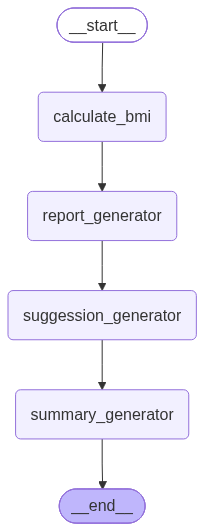

In [105]:
workflow

In [116]:
initial = {
    'height_m' : 1.64,
    'weight_kg' : 46
}

In [117]:
result = workflow.invoke(initial)

In [119]:
print(result['report'])

## Detailed Health Analysis Report

**Based on the provided metrics, this report offers an initial assessment of your current health status.**

---

### 1. Data Provided:

*   **Height:** 1.64 meters (5 feet 4.5 inches)
*   **Weight:** 46.0 kilograms (101.4 pounds)
*   **Body Mass Index (BMI):** 17.1

---

### 2. Analysis of Metrics:

*   **Height & Weight:** These are the foundational measurements used to calculate your Body Mass Index (BMI). They provide a direct snapshot of your physical size.

*   **Body Mass Index (BMI):**
    *   **Definition:** BMI is a widely used screening tool that estimates body fat based on a person's weight in relation to their height. It's calculated as weight (kg) divided by the square of height (m²).
    *   **Your Calculated BMI:** 17.1
    *   **Classification:** According to the World Health Organization (WHO) and standard health guidelines, a BMI of 17.1 falls into the **Underweight** category.
        *   Underweight: < 18.5
        *   Normal weig